Detected blocks:
  red  : pixel (167, 321) -> world (-0.33, -1.21) m   [true (-0.33, -1.22), error 0.8 cm]
  green: pixel (105, 206) -> world (-0.95, -0.06) m   [true (-0.95, -0.06), error 0.5 cm]
  blue : pixel (332, 301) -> world (1.32, -1.01) m   [true (1.33, -1.01), error 1.0 cm]
  Arm reached red   block at (-0.33, -1.21) m, joints = (-156 deg, 102 deg)
  Arm reached green block at (-0.95, -0.06) m, joints = (122 deg, 123 deg)
  Arm reached blue  block at (1.32, -1.01) m, joints = (-71 deg, 68 deg)


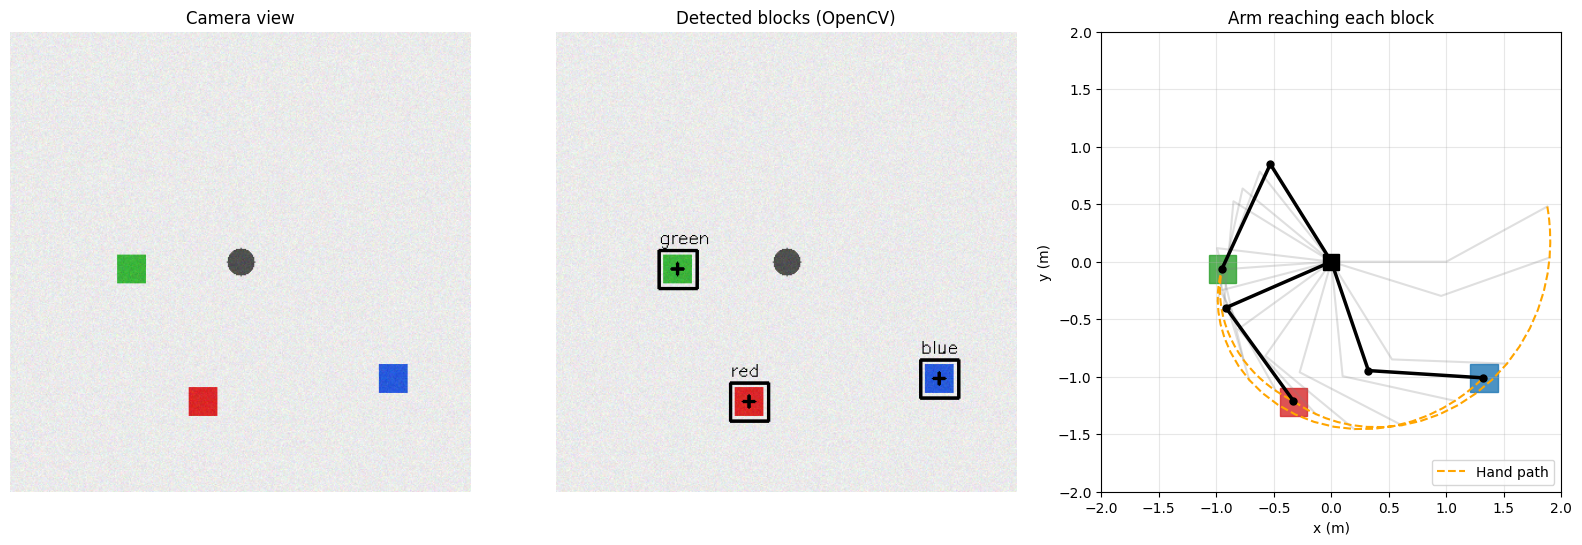

In [1]:
"""
Vision-Guided Robot Arm (Computer Vision + Robotics)

1. A top-down camera takes a picture of a table with coloured blocks.
2. Computer vision (OpenCV colour detection) finds each block in the image.
3. Pixel coordinates are converted to real-world table coordinates.
4. Inverse kinematics computes the joint angles of a 2-link robot arm.
5. The arm moves smoothly to each block, one after another.

Runs on Colab: opencv, numpy, matplotlib are preinstalled.
"""
import numpy as np
import cv2
import matplotlib.pyplot as plt

np.random.seed(3)

# ---------------- 1. Simulated camera image ----------------
IMG_SIZE = 400           # image is 400 x 400 pixels
WORLD_SIZE = 4.0         # it covers a 4 m x 4 m table, robot base at the centre
PX_PER_M = IMG_SIZE / WORLD_SIZE

def world_to_pixel(x, y):
    return int(IMG_SIZE / 2 + x * PX_PER_M), int(IMG_SIZE / 2 - y * PX_PER_M)

def pixel_to_world(u, v):
    return (u - IMG_SIZE / 2) / PX_PER_M, (IMG_SIZE / 2 - v) / PX_PER_M

# Blocks placed randomly within the arm's reach (0.6 to 1.8 m from base)
COLORS_BGR = {"red": (40, 40, 220), "green": (60, 180, 60), "blue": (220, 90, 40)}
true_positions = {}
image = np.full((IMG_SIZE, IMG_SIZE, 3), 235, np.uint8)           # light table
cv2.circle(image, world_to_pixel(0, 0), 12, (80, 80, 80), -1)     # robot base
for name, bgr in COLORS_BGR.items():
    r, ang = np.random.uniform(0.6, 1.8), np.random.uniform(0, 2 * np.pi)
    x, y = r * np.cos(ang), r * np.sin(ang)
    true_positions[name] = (x, y)
    u, v = world_to_pixel(x, y)
    cv2.rectangle(image, (u - 12, v - 12), (u + 12, v + 12), bgr, -1)

noise = np.random.normal(0, 8, image.shape)                       # camera noise
image = np.clip(image + noise, 0, 255).astype(np.uint8)

# ---------------- 2. Detect blocks with colour thresholding ----------------
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
HSV_RANGES = {   # (lower, upper) in OpenCV HSV (H: 0-179)
    "red":   [((0, 120, 80), (10, 255, 255)), ((170, 120, 80), (179, 255, 255))],
    "green": [((40, 100, 80), (80, 255, 255))],
    "blue":  [((100, 120, 80), (130, 255, 255))],
}

detections = {}
for name, ranges in HSV_RANGES.items():
    mask = sum(cv2.inRange(hsv, np.array(lo), np.array(hi)) for lo, hi in ranges)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        continue
    biggest = max(contours, key=cv2.contourArea)
    M = cv2.moments(biggest)
    u, v = M["m10"] / M["m00"], M["m01"] / M["m00"]               # centroid in pixels
    detections[name] = {"pixel": (u, v), "world": pixel_to_world(u, v),
                        "box": cv2.boundingRect(biggest)}

print("Detected blocks:")
for name, d in detections.items():
    wx, wy = d["world"]
    tx, ty = true_positions[name]
    err = np.hypot(wx - tx, wy - ty) * 100
    print(f"  {name:5s}: pixel ({d['pixel'][0]:.0f}, {d['pixel'][1]:.0f}) -> "
          f"world ({wx:.2f}, {wy:.2f}) m   [true ({tx:.2f}, {ty:.2f}), error {err:.1f} cm]")

# ---------------- 3. Robot arm: inverse kinematics ----------------
L1, L2 = 1.0, 1.0

def forward_kinematics(t1, t2):
    elbow = np.array([L1 * np.cos(t1), L1 * np.sin(t1)])
    hand = elbow + np.array([L2 * np.cos(t1 + t2), L2 * np.sin(t1 + t2)])
    return elbow, hand

def inverse_kinematics(x, y):
    """Joint angles (elbow-down solution) that put the hand at (x, y)."""
    c2 = (x**2 + y**2 - L1**2 - L2**2) / (2 * L1 * L2)
    t2 = np.arccos(np.clip(c2, -1, 1))
    t1 = np.arctan2(y, x) - np.arctan2(L2 * np.sin(t2), L1 + L2 * np.cos(t2))
    t1 = (t1 + np.pi) % (2 * np.pi) - np.pi        # keep angle in [-180, 180] deg
    return t1, t2

# ---------------- 4. Plan a smooth trajectory through all blocks ----------------
def smooth_move(q_start, q_end, steps=30):
    """Joint-space trajectory with smooth start/stop (cubic easing)."""
    s = np.linspace(0, 1, steps)
    s = 3 * s**2 - 2 * s**3
    dq = (np.array(q_end) - np.array(q_start) + np.pi) % (2 * np.pi) - np.pi  # shortest way
    return [np.array(q_start) + si * dq for si in s]

q = np.array([0.0, 0.5])          # home pose
trajectory, reached = [], []
for name, d in detections.items():
    q_goal = inverse_kinematics(*d["world"])
    trajectory += smooth_move(q, q_goal)
    q = np.array(q_goal)
    hand = forward_kinematics(*q)[1]
    reached.append((name, hand))
    print(f"  Arm reached {name:5s} block at ({hand[0]:.2f}, {hand[1]:.2f}) m, "
          f"joints = ({np.degrees(q[0]):.0f} deg, {np.degrees(q[1]):.0f} deg)")

# ---------------- 5. Plots ----------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))

# (a) camera image
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Camera view"); axes[0].axis("off")

# (b) detections
annotated = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()
for name, d in detections.items():
    x, y, w, h = d["box"]
    cv2.rectangle(annotated, (x - 4, y - 4), (x + w + 4, y + h + 4), (0, 0, 0), 2)
    cv2.putText(annotated, name, (x - 4, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1)
    cv2.drawMarker(annotated, (int(d["pixel"][0]), int(d["pixel"][1])), (0, 0, 0),
                   cv2.MARKER_CROSS, 10, 2)
axes[1].imshow(annotated)
axes[1].set_title("Detected blocks (OpenCV)"); axes[1].axis("off")

# (c) robot arm moving to each block
ax = axes[2]
plot_colors = {"red": "tab:red", "green": "tab:green", "blue": "tab:blue"}
hand_path = np.array([forward_kinematics(*qq)[1] for qq in trajectory])
for k in range(0, len(trajectory), 6):
    elbow, hand = forward_kinematics(*trajectory[k])
    ax.plot([0, elbow[0], hand[0]], [0, elbow[1], hand[1]], "-", color="gray", alpha=0.25)
ax.plot(hand_path[:, 0], hand_path[:, 1], "--", color="orange", label="Hand path")
for name, hand in reached:
    q_final = inverse_kinematics(*hand)
    elbow, _ = forward_kinematics(*q_final)
    ax.plot([0, elbow[0], hand[0]], [0, elbow[1], hand[1]], "-o", color="k", lw=2.5, ms=5)
    tx, ty = true_positions[name]
    ax.add_patch(plt.Rectangle((tx - 0.12, ty - 0.12), 0.24, 0.24,
                               color=plot_colors[name], alpha=0.8))
ax.plot(0, 0, "ks", ms=12)
ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("Arm reaching each block"); ax.legend(loc="lower right")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

plt.tight_layout()
plt.savefig("vision_robot_result.png", dpi=120)
plt.show()